# Tabular 회귀 — 실습용 완성 코드

위에서부터 순서대로 실행. **★ 설정**만 데이터에 맞게 바꾸면 됩니다.
확인이 필요한 판단(버릴 컬럼)은 **셀을 나눠** 출력을 보고 정합니다. (숫자 타겟 예측 · 지표 RMSE/MAE/R²)

> 변수명은 **이 파일 단독 실행** 기준(plain)입니다. 실습은 **한 커널**에서 3문제를 이어 풀어 `X`·`best`·`sub` 같은 변수가 서로 덮어써집니다 — 정형=`p1_`, 텍스트=`p2_`, 이미지=`p3_` 접두사로 문제별로 분리하세요.

## 1. 설정 · 로드  ← ★ 여기만 수정

In [1]:
import pandas as pd, numpy as np, joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
RESULT_1 = '01012345678_1'             # 휴대폰번호_문제번호 (하이픈·공백 없이). Tabular=1

# ▼ 데이터 선택 (하나만) — 회귀 예제는 전부 csv(콤마 구분)
TRAIN_URL = 'https://github.com/gzone2000/TEMP_TEST/raw/refs/heads/master/kc_house_data.csv'   # [1] 집값
# TRAIN_URL = 'https://github.com/gzone2000/TEMP_TEST/raw/refs/heads/master/ade_sales.csv'      # [2] 레모네이드
TEST_URL = None                        # test 파일 따로 있으면 URL, 없으면 None(train 에서 분리)

df_all = pd.read_csv(TRAIN_URL)                     # 원본(불변) — 분할은 타겟 정한 뒤 '3.' 에서
df_test_raw = pd.read_csv(TEST_URL) if TEST_URL else None
print('불러온 데이터:', df_all.shape, '| test 파일:', df_test_raw.shape if TEST_URL else '없음(train 에서 분리)')
df_all.head()

불러온 데이터: (21613, 21) | test 파일: 없음(train 에서 분리)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180.0,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170.0,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770.0,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050.0,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680.0,0,1987,0,98074,47.6168,-122.045,1800,7503


## 2. 데이터 확인  (컬럼·타입·결측을 보고 아래에서 맞출/버릴 컬럼을 정한다)

In [2]:
print(df_all.dtypes)
# 고유값이 행수에 가까운 컬럼 = ID/날짜 → 버릴 후보
print(); print('컬럼별 고유값 수:'); print(df_all.nunique().sort_values(ascending=False))
print(); print('결측:', df_all.isnull().sum()[lambda s: s > 0].to_dict())

id                 int64
date              object
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above       float64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

컬럼별 고유값 수:
id               21436
sqft_lot          9782
sqft_lot15        8689
lat               5034
price             4028
sqft_living       1038
sqft_above         946
sqft_living15      777
long               752
date               372
sqft_basement      306
yr_built           116
zipcode             70
yr_renovated        70
bathrooms           30
bedrooms            13
grade               12
floors               6
condition            5
view        

## 3. 맞출 컬럼 지정 · 분할  ← ★ 위 '데이터 확인'을 보고 채운다

In [3]:
# ★ 위 컬럼 목록에서 '맞출 컬럼(예측할 수치)'을 직접 지정 (지문이 준 이름과 철자 일치 확인)
TARGET = 'price'             # [1] 집값 · [2] 레모네이드:'Lemon'
PRED_COL = TARGET            # 제출 결과 컬럼명 — 지문이 다른 이름을 지정하면 그 이름으로 바꾼다

print('타겟 통계:'); print(df_all[TARGET].describe()[['mean', 'min', 'max']])

# test 가 따로 없으면 여기서 분리 (회귀는 stratify 없음). df_all 은 원본이라 재실행해도 안전
if df_test_raw is None:
    df, df_test = train_test_split(df_all, test_size=0.2, random_state=SEED)
else:
    df, df_test = df_all.copy(), df_test_raw.copy()
df, df_test = df.reset_index(drop=True), df_test.reset_index(drop=True)
df_test_orig = df_test.copy()          # 제출은 test 원본 구조로
print('Train', df.shape, '/ Test', df_test.shape)

타겟 통계:
mean    5.400881e+05
min     7.500000e+04
max     7.700000e+06
Name: price, dtype: float64
Train (17290, 21) / Test (4323, 21)


## 4. 상관 히트맵  (숫자 컬럼 ↔ 타겟)

타겟과 상관이 강한 컬럼 = 좋은 예측변수. **|r|이 1에 가까우면 누수** 의심(드롭 후보).
숫자 컬럼만 계산하며, 문자 타겟은 상관 계산을 위해 임시 인코딩합니다.

타겟과 상관(|r|) 상위:
{'sqft_living': 0.702, 'grade': 0.665, 'sqft_above': 0.603, 'sqft_living15': 0.583, 'bathrooms': 0.527, 'view': 0.392, 'sqft_basement': 0.321, 'lat': 0.311, 'bedrooms': 0.308, 'floors': 0.253}


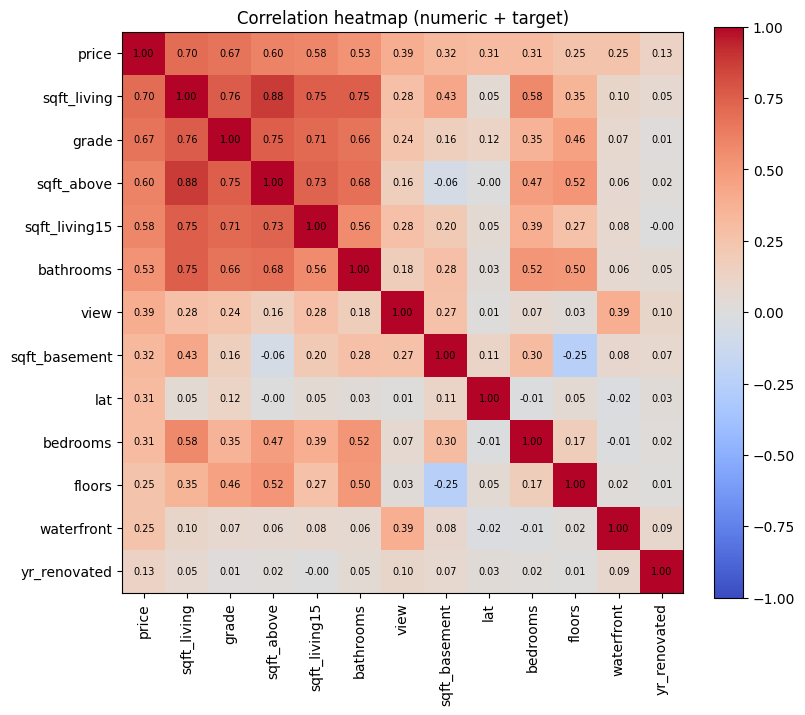

In [4]:
import matplotlib.pyplot as plt
num = df.select_dtypes('number').copy()
if TARGET not in num.columns:                       # 문자 타겟이면 상관 계산 위해 임시 인코딩
    num[TARGET] = LabelEncoder().fit_transform(df[TARGET].astype(str))
corr = num.corr(numeric_only=True)

# 타겟과 상관 큰 순 (|r|=1 이면 누수 의심, 클수록 강한 예측변수)
tcorr = corr[TARGET].drop(TARGET).abs().sort_values(ascending=False)
print('타겟과 상관(|r|) 상위:'); print(tcorr.head(10).round(3).to_dict())

# 컬럼이 많으면(>15) 타겟 + 상관 상위 12개만 그린다 (전체는 너무 커서 안 보임)
cols = ([TARGET] + tcorr.head(12).index.tolist()) if len(corr) > 15 else corr.columns.tolist()
cm = corr.loc[cols, cols]
plt.figure(figsize=(min(1 + 0.55 * len(cols), 11), min(1 + 0.55 * len(cols), 11)))
plt.imshow(cm, cmap='coolwarm', vmin=-1, vmax=1); plt.colorbar(fraction=0.046)
plt.xticks(range(len(cols)), cols, rotation=90); plt.yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f'{cm.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.title('Correlation heatmap (numeric + target)'); plt.tight_layout(); plt.show()

## 5. 버릴 컬럼 결정  ← ★ 위 '데이터 확인'을 보고 채운다

In [5]:
# ── 버릴 후보 자동 점검 (참고용, df=train 기준) ──
n = len(df)
card = (df.drop(columns=[TARGET]).nunique() / n).sort_values(ascending=False)
print('① 고유값/행수 비율(1에 가까울수록 ID·날짜 후보):')
print('  ', {k: round(v, 3) for k, v in card.head(6).items()})
print('   → 비율 0.9 초과:', [c for c in card.index if card[c] > 0.9] or '없음')
# ② 그 컬럼값만 알면 타겟이 하나로 정해지는 컬럼 = 누수 의심 (ID 는 nunique<n 으로 제외)
leak = [c for c in df.columns if c != TARGET and 1 < df[c].nunique() < n
        and df.groupby(c)[TARGET].nunique().max() == 1]
print('② 타겟과 완벽히 일치(누수 의심):', leak or '없음')

# ★ 위 ①②와 상식을 보고 버릴 컬럼을 직접 적는다 (날짜·문자열 식별자 포함)
DROP_COLS = ['id', 'date']             # [1] 집값
# [2] 레모네이드: DROP_COLS = ['Date']
print('버릴 컬럼:', [c for c in DROP_COLS if c in df.columns])
print('남는 피처:', [c for c in df.columns if c not in DROP_COLS + [TARGET]])

① 고유값/행수 비율(1에 가까울수록 ID·날짜 후보):
   {'id': 0.994, 'sqft_lot': 0.486, 'sqft_lot15': 0.437, 'lat': 0.28, 'sqft_living': 0.053, 'sqft_above': 0.049}
   → 비율 0.9 초과: ['id']
② 타겟과 완벽히 일치(누수 의심): 없음
버릴 컬럼: ['id', 'date']
남는 피처: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


## 6. 전처리  (결측 → 인코딩 → 스케일)

In [6]:
has_y_test = TARGET in df_test.columns
X      = df.drop(columns=[c for c in DROP_COLS + [TARGET] if c in df.columns], errors='ignore')
X_test = df_test.drop(columns=[c for c in DROP_COLS + [TARGET] if c in df_test.columns], errors='ignore')
y      = df[TARGET].astype(float)                      # 회귀 타겟(연속값) — 인코딩 안 함
y_test = df_test[TARGET].astype(float) if has_y_test else None

# 수치형/범주형 분리 — 결측 채우는 방법이 다르므로 먼저 나눈다
num = X.select_dtypes('number').columns.tolist()
cat = [c for c in X.columns if c not in num]

# 결측치 채우기 — ★ train 에서 fit → test 는 transform (test 로 fit 하면 누수)
if num:
    imp_n = SimpleImputer(strategy='median')           # 수치형: 중앙값
    X[num] = imp_n.fit_transform(X[num]); X_test[num] = imp_n.transform(X_test[num])
if cat:
    imp_c = SimpleImputer(strategy='most_frequent')    # 범주형: 최빈값
    X[cat] = imp_c.fit_transform(X[cat]); X_test[cat] = imp_c.transform(X_test[cat])

# 범주형 인코딩 (train 사전으로 test 변환, 미지값은 -1)
for col in cat:
    le = LabelEncoder().fit(X[col].astype(str)); m = {v: i for i, v in enumerate(le.classes_)}
    X[col] = X[col].astype(str).map(m)
    X_test[col] = X_test[col].astype(str).map(m).fillna(-1).astype(int)

# 스케일링
sc = StandardScaler()
X = pd.DataFrame(sc.fit_transform(X), columns=X.columns)
X_test = pd.DataFrame(sc.transform(X_test), columns=X_test.columns)
print('수치형', len(num), '· 범주형', len(cat))

수치형 18 · 범주형 0


## 7. 모델 비교 · 학습 · 평가  (RMSE · MAE · R²)

In [7]:
def rmse(a, b): return np.sqrt(mean_squared_error(a, b))
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.2, random_state=SEED)

models = {
    'Linear':       LinearRegression(),
    'RandomForest': RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
    'GradBoost':    GradientBoostingRegressor(random_state=SEED),
}
cv = {n: cross_val_score(m, Xtr, ytr, cv=5, scoring='r2').mean() for n, m in models.items()}
best_name = max(cv, key=cv.get)
best = models[best_name].fit(Xtr, ytr)
print('CV R²:', {n: round(s, 4) for n, s in cv.items()}, '→ 1위', best_name)

pv = best.predict(Xva)
print(f'Val RMSE {rmse(yva, pv):.3f} / MAE {mean_absolute_error(yva, pv):.3f} / R² {r2_score(yva, pv):.4f}')

CV R²: {'Linear': np.float64(0.6943), 'RandomForest': np.float64(0.8716), 'GradBoost': np.float64(0.867)} → 1위 RandomForest
Val RMSE 119235.951 / MAE 67854.980 / R² 0.8805


## 8. 결과 만들고 ⭐ 눈으로 확인

> 예측값 범위가 상식적인지, 컬럼/행수 이상 없는지 **저장 전에** 눈으로 봅니다.

In [10]:
pred = best.predict(X_test)

sub = df_test_orig.drop(columns=[c for c in [TARGET] if c in df_test_orig.columns]).copy()
sub[PRED_COL] = pred

print('행수', len(sub), '| 컬럼', list(sub.columns))
print('예측 요약:', {'min': round(float(pred.min()), 1), 'mean': round(float(pred.mean()), 1), 'max': round(float(pred.max()), 1)})
if has_y_test:
    print('Test RMSE', round(rmse(y_test, pred), 3), '/ R²', round(r2_score(y_test, pred), 4))
sub.head(10)

행수 4323 | 컬럼 ['id', 'date', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'price']
예측 요약: {'min': 144347.6, 'mean': 548464.0, 'max': 5517795.2}
Test RMSE 146941.292 / R² 0.8572


,id,date,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,price
0,2591820310,20141006T000000,4,2.25,2070,8893,2.0,0,0,4,...,2070.0,0,1986,0,98058,47.4388,-122.162,2390,7700,3.819393e+05
1,7974200820,20140821T000000,5,3.00,2900,6730,1.0,0,0,5,...,1830.0,1070,1977,0,98115,47.6784,-122.285,2370,6283,8.170808e+05
2,7701450110,20140815T000000,4,2.50,3770,10893,2.0,0,2,3,...,3770.0,0,1997,0,98006,47.5646,-122.129,3710,9685,1.138893e+06
3,9522300010,20150331T000000,3,3.50,4560,14608,2.0,0,2,3,...,4560.0,0,1990,0,98034,47.6995,-122.228,4050,14226,2.088973e+06
4,9510861140,20140714T000000,3,2.50,2550,5376,2.0,0,0,3,...,2550.0,0,2004,0,98052,47.6647,-122.083,2250,4050,7.116608e+05
5,1761300310,20140827T000000,4,2.00,1710,8288,1.5,0,0,3,...,1710.0,0,1970,0,98031,47.3947,-122.174,1710,7200,2.531300e+05
6,7732410120,20140819T000000,4,2.50,2690,8036,2.0,0,0,4,...,2690.0,0,1987,0,98007,47.6596,-122.144,2420,8087,8.500687e+05
7,7010701383,20141017T000000,3,2.50,1800,4400,1.0,0,0,5,...,1350.0,450,1970,0,98199,47.6599,-122.396,1920,4400,6.388193e+05
8,291310170,20140804T000000,3,2.50,1600,2610,2.0,0,0,3,...,1600.0,0,2005,0,98027,47.5344,-122.068,1445,1288,4.219945e+05
9,4232901990,20140516T000000,2,1.00,910,3600,1.0,0,0,4,...,910.0,0,1909,0,98119,47.6341,-122.361,1720,3600,5.160158e+05


## 9. ⭐ csv · 모델 저장

> 위 결과가 이상 없으면 저장. `RESULT_1.csv` + 모델(`.pkl`), `index=False` 필수.

In [11]:
import os
CSV, MODEL = f'{RESULT_1}.csv', f'{RESULT_1}.pkl'
assert len(sub) == len(df_test_orig), '행 수 불일치'      # ★ 저장 전에 검증 (0점 나는 두 원인)
assert sub[PRED_COL].isnull().sum() == 0, '예측 결측'
sub.to_csv(CSV, index=False)     # 결과 csv
joblib.dump(best, MODEL)                                # 모델
print('저장 완료:', [f for f in os.listdir('.') if f.startswith(RESULT_1)])

저장 완료: ['01012345678_1.pkl', '01012345678_1.csv']
